# 02 - Model Training and Evaluation
Trains Logistic Regression and Random Forest on the same stratified split, tunes with 5-fold CV on training data only, and evaluates on the held-out test set. Every number below is produced by running the code.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import pandas as pd
from src.train_model import train_models, list_trained_models
from src.evaluate_model import evaluate_all, threshold_table
from src.data_preprocessing import MODELS_DIR, REPORTS_DIR, FIGURES_DIR
from IPython.display import Image, display

## 1. Train (skipped if models already exist)
Imbalance is handled with `class_weight='balanced'`: errors on the rarer churn class cost more, with no fake rows and no change to the test set. Tuning uses ROC-AUC under stratified 5-fold CV.

In [2]:
if len(list_trained_models()) < 2:
    train_models()
else:
    print('Models already trained:', list_trained_models())
print(open(MODELS_DIR / 'training_metadata.json').read())

Models already trained: ['logistic_regression', 'random_forest']
{
  "trained_at_utc": "2026-10-25T02:25:09+00:00",
  "random_state": 42,
  "test_size": 0.2,
  "n_train": 5634,
  "n_test": 1409,
  "churn_rate_train": 0.2654,
  "sklearn_version": "1.8.0",
  "models": {
    "logistic_regression": {
      "best_params": {
        "model__C": 10
      },
      "cv_roc_auc": 0.8462,
      "seconds": 1.8
    },
    "random_forest": {
      "best_params": {
        "model__max_depth": 10,
        "model__min_samples_leaf": 5,
        "model__n_estimators": 200
      },
      "cv_roc_auc": 0.8473,
      "seconds": 79.7
    }
  }
}


## 2. Evaluate on the test set

In [3]:
comparison = evaluate_all()
comparison

,accuracy,precision,recall,f1,f2,roc_auc,tn,fp,fn,tp,selected
model,,,,,,,,,,,
logistic_regression,0.7388,0.5052,0.7834,0.6143,0.7057,0.8406,748,287,81,293,True
random_forest,0.7594,0.5332,0.7513,0.6238,0.6945,0.8422,789,246,93,281,False


**How to read this**
- **False positive (FP):** we flag a customer who would have stayed - cost: a possibly unnecessary retention offer.
- **False negative (FN):** we miss a customer who then leaves - cost: lost revenue and no chance to intervene.
- **Recall** = share of real churners we catch. It matters most when missing a churner is costlier than a wasted offer.
- **ROC-AUC** measures how well the model *ranks* churners above non-churners at every threshold, so it complements accuracy, which depends on one threshold and on the class balance.
- **Final model rule:** highest F2 (recall counts twice as much as precision), ROC-AUC breaking ties. Accuracy is not used. This choice is made on the test set, so a fresh validation set would be needed for a strictly unbiased pick.

## 3. Confusion matrices and ROC curves

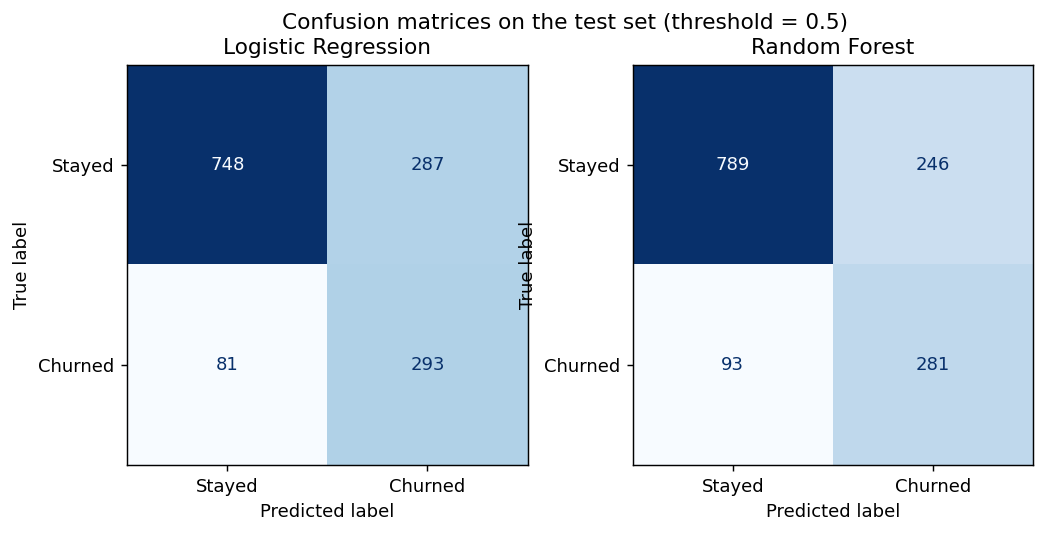

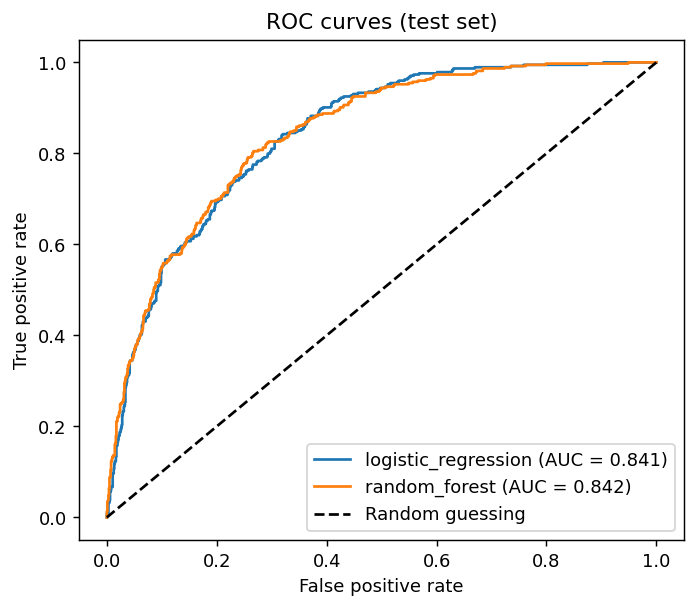

In [4]:
display(Image(str(FIGURES_DIR / 'confusion_matrices.png')))
display(Image(str(FIGURES_DIR / 'roc_curves.png')))

## 4. Threshold effect (selected model)

,threshold,precision,recall,f1,customers_flagged_%
0,0.05,0.311,0.995,0.474,84.812
1,0.10,0.342,0.989,0.508,76.792
2,0.15,0.368,0.979,0.535,70.617
3,0.20,0.390,0.963,0.556,65.436
4,0.25,0.409,0.939,0.570,60.894
5,0.30,0.430,0.928,0.588,57.275
6,0.35,0.445,0.901,0.595,53.797
7,0.40,0.462,0.864,0.602,49.610
8,0.45,0.488,0.840,0.617,45.706
9,0.50,0.505,0.783,0.614,41.164


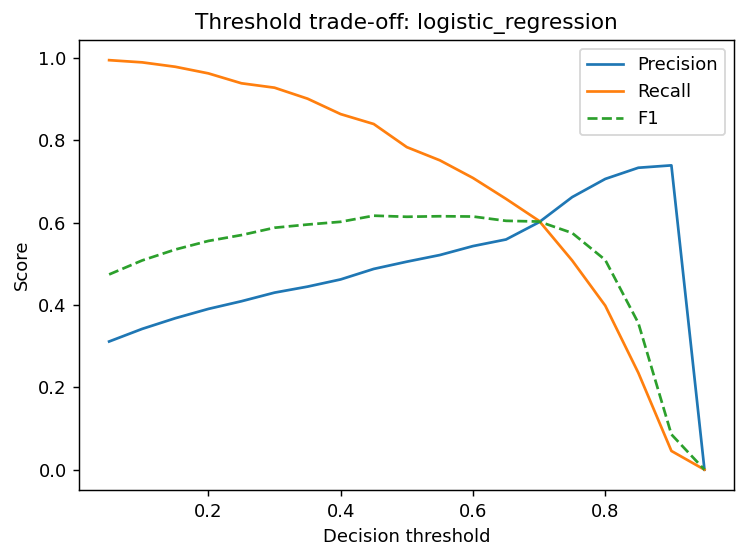

In [5]:
t = pd.read_csv(REPORTS_DIR / 'threshold_analysis.csv')
display(t.round(3))
display(Image(str(FIGURES_DIR / 'threshold_tradeoff.png')))

Raising the threshold flags fewer customers: precision rises, recall falls. Lowering it catches more churners but also flags many who would have stayed. The right value depends on the cost of a retention offer versus a lost customer.

## 5. Feature importance

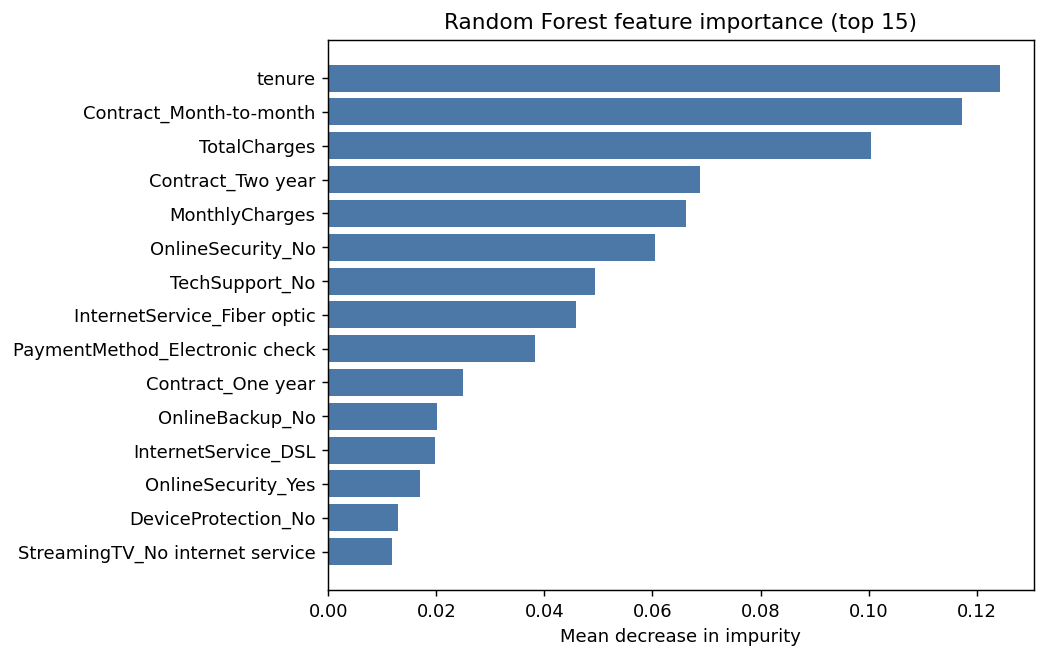

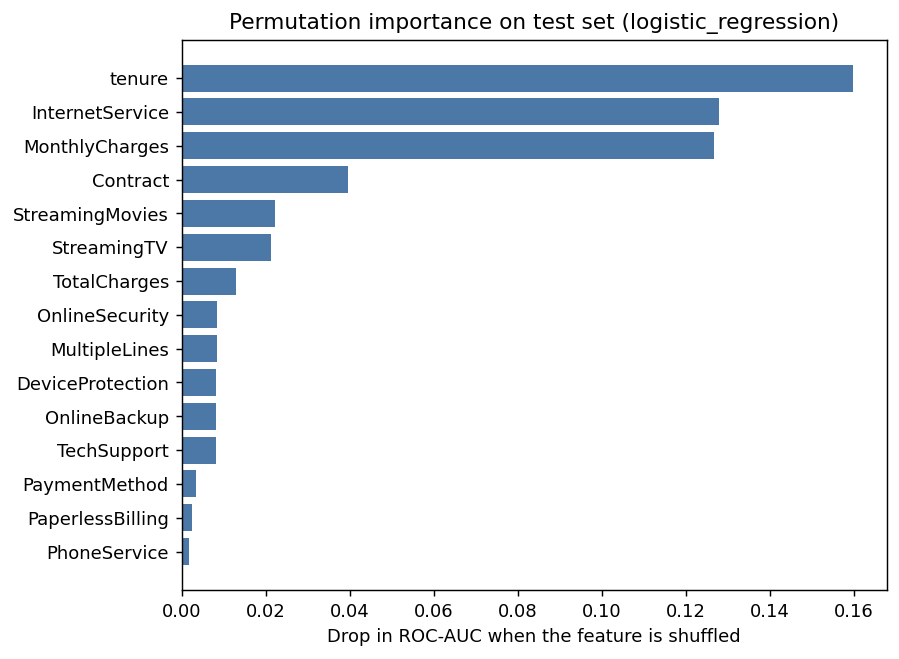

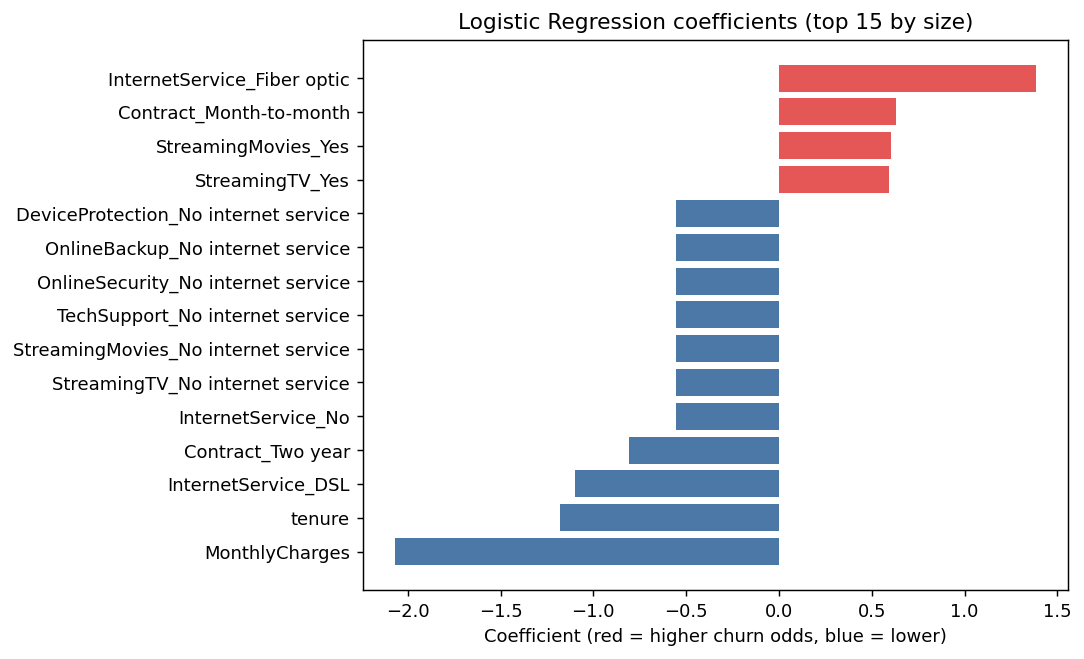

,feature,mean_drop_in_auc,std
0,tenure,0.1598,0.0048
1,InternetService,0.1279,0.0126
2,MonthlyCharges,0.1268,0.0111
3,Contract,0.0397,0.0041
4,StreamingMovies,0.0223,0.0035
5,StreamingTV,0.0212,0.0047
6,TotalCharges,0.0129,0.0024
7,OnlineSecurity,0.0085,0.0028


In [6]:
for f in ['rf_feature_importance.png', 'permutation_importance.png', 'lr_coefficients.png']:
    display(Image(str(FIGURES_DIR / f)))
pd.read_csv(REPORTS_DIR / 'permutation_importance.csv').head(8).round(4)

Permutation importance (on held-out data) shows `tenure`, `InternetService`, `MonthlyCharges` and `Contract` as the features whose shuffling hurts ROC-AUC most for the selected model. The Random Forest's own importance also ranks tenure, month-to-month contract and charges highly.

**Caution:** these are *associations learned by the model*, not proven causes. Features such as tenure, price and contract overlap, so importance can be shared between them. Changing a feature for a customer will not necessarily change whether they leave.